In [1]:
## a useful function to generate a data list for further analysis
import os,json,sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from analyse_stimulus_evoked_response import main
##need to add this additional cell because useful tools are in another folder. Need to integrate these two folders one day
current_working_directory = Path.cwd()
parent_dir = current_working_directory.resolve().parents[0]
sys.path.insert(0, str(parent_dir) + "\\utilities")
from useful_tools import select_animals_gpt, find_file
from data_cleaning import preprocess_fictrac_data

Transition indices: [2 4 7]


Session 0.1: Load analysis methods in python dictionary form

In [2]:
sheet_name="MatrexVR"
#sheet_name="VCCball"
#sheet_name="Zball"
json_file = "./analysis_methods_dictionary.json"
with open(json_file, "r") as f:
    analysis_methods = json.loads(f.read())
    

Datasets="Z:/DATA/experiment_trackball_Optomotor"
this_dataset_dir = f"{Datasets}/{sheet_name}"

In [4]:
from scipy.io import savemat
with open(r'Z:\DATA\experiment_trackball_Optomotor\MatrexVR\matrex_vr_coherence_database_yaw_vector.pickle', 'rb') as file:
    data = pd.read_pickle(file)
data_dict = {name: col.values for name, col in data.items()}
savemat(r'Z:\DATA\experiment_trackball_Optomotor\MatrexVR\matrex_vr_coherence_database.mat', data_dict)

Session 0.2: Load animal directory as a list

In [ ]:
## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the dat file in that folder.
## In this project, we usually have one dat file in that folder so there is no confusion
dir_list = []
file_type=".dat"
for root, dirs, files in os.walk(this_dataset_dir):
    if analysis_methods.get("experiment_name") in root.split(
        os.path.sep
    ):  ## add this condition to avoid data from other experiments
        for folder in dirs:
            if folder.startswith("session"):
                folder_path=os.path.join(root,folder)
                if any(name.endswith(file_type) for name in os.listdir(folder_path)):
                    dir_list.append(folder_path.replace("\\", "/"))
print(f"these directories are found {dir_list}")

Session 1.0: Create curated dataset based on the list of directories

In [ ]:
pattern="database*.pickle"
for this_dir in dir_list:
    if any(Path(this_dir).glob(pattern)) and analysis_methods.get("overwrite_curated_dataset")==False:
        print(f"curated fictrac data found in {this_dir}. Skip this file")
        continue
    else:
        print(f"no curated fictrac data in {this_dir}. Create curated file")
        preprocess_fictrac_data(this_dir,analysis_methods)

In [3]:
# Define the path to your Excel file
dir_list = []
# choose folders that contains fictrac .dat file
file_type=".dat"
using_google_sheet=True
experiment_name=analysis_methods.get("experiment_name")
if analysis_methods.get("load_experiment_condition_from_database") == True:
    if using_google_sheet==True:
        database_id = "1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8"
                #https://docs.google.com/spreadsheets/d/1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8/edit?usp=sharing
        url = f"https://docs.google.com/spreadsheets/d/{database_id}/gviz/tq?tqx=out:csv&sheet={sheet_name}"
        #df = pd.read_excel(url, engine='openpyxl')## use this function if the file is not google sheet but uploaded excel file

        df = pd.read_csv(url)
    else:
        excel_file_path = "Z:/DATA/experiment_trackball_Optomotor/Locusts Management.xlsx"
        print(f"using a database {excel_file_path} from the server but this file might be outdated")
        # Create a 'with' statement to open and read the Excel file
        with pd.ExcelFile(excel_file_path) as xls:
            # Read the Excel sheet into a DataFrame with the sheet name (folder name)
            df = pd.read_excel(xls, sheet_name)
        ##list up the conditions and answers as strings for input argument to select animal. One condition must pair with one answer
    if analysis_methods.get("select_animals_by_condition") == True:
        #animal_of_interest=select_animals_gpt(df,"Stimulus Type (list up all the stimulus paradigm this animal receive)","densities","Exluding this animal from analysis (Usually when animals die or molt, T/F)","F","Housing Condition before the experiment","gregarious")
        animal_of_interest=select_animals_gpt(df,"Excluding this animal from analysis (Usually when animals die or molt, T/F)","F")
        #print(animal_of_interest)
    else:
        animal_of_interest=df
    ID_array=animal_of_interest["ID"].values
    dir_list = [
    root.replace("\\", "/")
    for root, dirs, files in os.walk(this_dataset_dir)
    if any(ID in root for ID in ID_array)
    and experiment_name in root.split(os.path.sep)
    and any(name.endswith(file_type) for name in files)
]
else:
    ## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the hdf5 file in that folder.
    ## However,some changes need to be made once we do sleap or deeplabcut where there are more than one H5 file generated
    for root, dirs, files in os.walk(this_dataset_dir):
        if analysis_methods.get("experiment_name") in root.split(os.path.sep):## add this condition to avoid data from other experiments
            if any(name.endswith(file_type) for name in files):
                dir_list.append(root.replace("\\", "/"))

In [5]:
dir_list=dir_list[8:]

Session 2.1: Analyse optomotor response

In [ ]:
# because the import does not update the new version of python.
# Need to restart kernel 
summary_list=[]
output1_across_exp=[]
output2_across_exp=[]
output3_across_exp=[]
output4_across_exp=[]
for this_dir in dir_list:
    if "archive" in this_dir:
        print(f"skip archive folder for {this_dir}")
        continue
    summary,speed,rotation,travel_distance_whole_session=main(this_dir,analysis_methods)
    summary_list.append(summary)
    output1_across_exp.append(speed)
    output2_across_exp.append(rotation)
    output3_across_exp.append(travel_distance_whole_session)
    output4_across_exp.append(this_dir)

Session 2.2: add meta data

In [8]:
#If I ever want to add path and vid to every single row of the summary
from itertools import chain, repeat
#https://stackoverflow.com/questions/14878538/duplicate-elements-in-a-list
ll = list(chain.from_iterable(repeat(e, speed.shape[0]) for e in output4_across_exp))
camera_num=[]
video_pattern="camera*.mp4"
#final_list = list((lambda id: find_file(id,video_pattern).stem.split("_")[0], output4_across_exp))
for id in ll:
    found_result=find_file(id,video_pattern)
    camera_num.append(found_result.stem.split("_")[0])

In [9]:
df=pd.DataFrame(pd.concat(summary_list,axis=0, ignore_index=True))
new_data = {'Path': ll, 'VR_no': camera_num}
df = df.assign(**new_data)
growth_condition='g'
df.insert(0, 'growth_condition', np.repeat(growth_condition,summary_list[0].shape[0]*len(summary_list)).tolist())
df.insert(0, 'ID', np.repeat(np.arange(len(output4_across_exp)),summary_list[0].shape[0]).tolist())

In [24]:
#if you want to wrap other matrix into pandas dataframe
c_name_list=[]
for i in range(output2_across_exp[0].shape[1]):
    c_name_list.append(f"ori_f{i}")
tmp=pd.DataFrame(np.vstack(output2_across_exp),columns=c_name_list)
df_rest_index=df.reset_index(drop=True)
tmp=tmp.reset_index(drop=True)
df_combined=pd.concat([df_rest_index, tmp], axis=1)

Session 2.3: save the database

In [11]:
#file_name="density_gregarious_database.pickle"
file_name="matrex_vr_coherence_database.pickle"
df.to_pickle(Path(this_dataset_dir)/file_name)

In [14]:
from scipy.io import savemat
data_dict = {name: col.values for name, col in df.items()}
summary_file_name = Path(this_dataset_dir) /"behavioural_summary.mat"
savemat(summary_file_name, data_dict)

In [22]:
df_rotation=np.concatenate(output2_across_exp)
summary_file_name = Path(this_dataset_dir) /"rotation_summary.npy"
np.save(summary_file_name, df_rotation)

In [26]:
file_name="matrex_vr_coherence_database_yaw_ori.pickle"
df_combined.to_pickle(Path(this_dataset_dir)/file_name)

In [ ]:
'''
df.to_csv(file_name)#file will be big when dataset is big
df.to_pickle(file_name)#easy to save
df.to_feather(file_name)#needs pyarrow and column names needs to be string
path_name = r'Z:\DATA\experiment_trackball_Optomotor\ANALYSIS\Sercan et al\density_database.parquet.gzip'
finished.to_parquet(path_name,compression='gzip')
df.to_hdf(file_name, key='solitarious', mode='w')#better used in dataset that has certain structure
'''

extra Session 2.1: Analyse optomotor response with multi-engines

In [ ]:
##this cell start the multi-engines. Make sure to run only once
import time
import ipyparallel as ipp
def show_clusters():
    clusters = ipp.ClusterManager().load_clusters() 
    print("{:15} {:^10} {}".format("cluster_id", "state", "cluster_file")) 
    for c in clusters:
        cd = clusters[c].to_dict()
        cluster_id = cd['cluster']['cluster_id']
        controller_state = cd['controller']['state']['state']
        cluster_file = getattr(clusters[c], '_trait_values')['cluster_file']
        print("{:15} {:^10} {}".format(cluster_id, controller_state, cluster_file))
    return cluster_id

cluster = ipp.Cluster(n=6)
await cluster.start_cluster()
cluster_neuropc=show_clusters()

In [ ]:
cluster_neuropc=show_clusters()

In [ ]:
##input cluster_id from previous cell
rc = ipp.Client(cluster_id=cluster_neuropc)

# Create a DirectView for parallel execution
dview = rc.direct_view()

# Define a function for parallel processing
def process_directory(this_dir, analysis_methods):
    from analyse_stimulus_evoked_response import main
    # Check if the H5 file (curated dataset) exists
    summary,speed,rotation,travel_distance_whole_session=main(this_dir,analysis_methods)
    return (summary,speed,rotation,travel_distance_whole_session)

# Define analysis_methods

# Use parallel execution to process directories
results = dview.map_sync(process_directory, dir_list, [analysis_methods] * len(dir_list))

# Initialize result lists
summary_list=[]
output1_across_exp=[]
output2_across_exp=[]
output3_across_exp=[]
output4_across_exp=[]

# Collect and organize results
for result in results:
    if result is not None:
        summary,speed,rotation = result
        summary_list.append(summary)
        output1_across_exp.append(speed)
        output2_across_exp.append(rotation)
        output3_across_exp.append(travel_distance_whole_session)
        output4_across_exp.append(this_dir)

# Now, you have the results collected in the respective lists

In [ ]:
rc.shutdown()

Session 2.5: Load existing dataset

In [ ]:
#database_pattern = "matrexVR_coherence_database.pickle"
database_pattern = "matrex_vr_coherence_database_yaw_ori.pickle"
load_existing_dataset=True
this_database = find_file(this_dataset_dir, database_pattern)
velocity_pattern="velocity*.npy"
jaw_vector_pattern="*jaw_rotation.npy"
summary_pattern="behavioural*.pickle"
pattern_list=[velocity_pattern,jaw_vector_pattern,summary_pattern]
print(f"loading this {this_database}")
if this_database is None or this_database.is_file()==False:
    print("no post-analysis database created. Either run analysis cell to get the list of animal's response or assemble post-analysis dataset from individual animals")
    if len(summary_list)>0:
    #if 'summary_list' in locals():
        df=pd.DataFrame(pd.concat(summary_list))
        print("use local list created from jupyter notebook")
    else:
        velocity_list=[]
        summary_list=[]
        rotation_list=[]
        for this_pattern in pattern_list:
            for this_dir in dir_list:
                this_file = find_file(this_dir, this_pattern)
                if this_file.suffix==".npy":
                    print({f"npy file is found. Let's assemble them"})
                    if this_pattern==velocity_pattern:
                        velocity_list.append(np.load(this_file))
                    elif this_pattern==jaw_vector_pattern:
                        rotation_list.append(np.load(this_file))
                elif this_file.suffix==".pickle":
                    print({f"load individual animal's summary"})
                    summary_list.append(pd.read_pickle(this_file))
                else:
                    print({f"no particular file created in this path: {this_dir}. Skip this animal"})
                

        df_velocity=np.concatenate(velocity_list)
        df_rotation=np.concatenate(rotation_list)
        df=pd.DataFrame(pd.concat(summary_list,axis=0, ignore_index=True))
elif load_existing_dataset==True:
    df=pd.read_pickle(this_database)
    df.rename(columns = {'Unnamed: 0':'trial_number'}, inplace = True)
    print("load pickle into pandas dataframe")
else:
    print("do not know what to do here")

In [57]:
analysis_methods.update({"debug_mode": False})

Session 3: plotting data

In [27]:
##introduce some helper class to define colour gradient
import matplotlib as mpl
from matplotlib import cm
class MplColorHelper:
    def __init__(self, cmap_name, start_val, stop_val):
        self.cmap_name = cmap_name
        self.cmap = plt.get_cmap(cmap_name)
        self.norm = mpl.colors.Normalize(vmin=start_val, vmax=stop_val)
        self.scalarMap = cm.ScalarMappable(norm=self.norm, cmap=self.cmap)

    def get_rgb(self, val):
        return self.scalarMap.to_rgba(val)
colormap_name = "coolwarm"
COL = MplColorHelper(colormap_name, 0, len(df["stim_type"].unique()))
sm = cm.ScalarMappable(cmap=colormap_name)

In [28]:
def plot_preview_summary(df,analysis_methods,vr_no="all"):
    debug_mode= analysis_methods.get("debug_mode")
    visual_paradigm_name= analysis_methods.get("experiment_name")
    colormap = np.array(analysis_methods.get("graph_colour_code"))
    premature_turn=0.25#set this criteria to remove animals starting to make turn turing ISI
    #print(colormap)
    fig, axes = plt.subplots(
        nrows=2, ncols=2, figsize=(18, 14), tight_layout=True
    )
    ax1, ax2, ax3, ax4 = axes.flatten()
    num_bins=10
    n, bins, patches = ax1.hist(df.groupby(['ID'])['travel_distance'].sum().values,num_bins,color=colormap[3])
    ax1.set(
    ylabel="Count",
    xlabel="Walk distance (mm)")
    threshold=40000
    for id, entries in df.groupby(['ID']):
        if entries["travel_distance"].sum()>threshold:
            above_threshold=True
        else:
            above_threshold=False
        #this_animal = df.loc[df['ID']==idx]
        entries=entries[abs(entries["opto_index_isi"])<premature_turn]
        for idx, this_stim in entries.groupby("stim_type"):
            this_response=this_stim["opto_index"].values
        # follow_count_coherence = tmp.index.values
        # for j in range(len(this_animal.groupby("stim_type"))):
            #this_coherence=follow_count_coherence[j]
            # this_response = this_animal.loc[
            #     this_animal["stim_type"] == this_coherence, "opto_index"
            # ].values
            mean_response = np.mean(this_response, axis=0)
            sem_response = np.std(this_response, axis=0, ddof=1) / np.sqrt(
                this_response.shape[0]
            )
            if above_threshold == True:
                this_colour=colormap[5]
            else:
                this_colour=colormap[6]
            ax2.errorbar(
                idx,
                mean_response,
                yerr=sem_response,
                c=this_colour,
                fmt="o",
                elinewidth=2,
                capsize=3,
            )
    ax2.set_ylim(-1, 1)

    if visual_paradigm_name =="gratings":
        xlabel="Temporal frequency (Hz)"
    elif visual_paradigm_name =="coherence":
        xlabel="Coherence (%)"
    ax2.set(
        yticks=[-1,0,1],
        ylabel="Optomotor Index",
        xlabel=xlabel)
        
    num_bins=100
    n, bins, patches = ax3.hist(df['travel_distance'].values,num_bins,density=True,range=(0,1500),color=colormap[3])
    ax3.set(
    ylabel="Density",
    xlabel="Walk distance (mm)")
    walk_threshold=25
    df=df[(df['travel_distance']>walk_threshold) & (abs(df["opto_index_isi"])<premature_turn)]
    for this_coherence,entries in df.groupby("stim_type"):
        this_response = entries["opto_index"].values
        mean_response = np.mean(this_response, axis=0)
        sem_response = np.std(this_response, axis=0, ddof=1) / np.sqrt(this_response.shape[0])
        ax4.errorbar(
            this_coherence,
            mean_response,
            yerr=sem_response,
            c=colormap[0],
            fmt="o",
            elinewidth=2,
            capsize=3,
        )
    ax4.set_ylim(-1, 1)
    ax4.set(
        yticks=[-1,-0.5,0,0.5,1],
        ylabel="Optomotor Index",
        xlabel=xlabel)
    fig.suptitle(f'The response of locusts during {visual_paradigm_name} stimulus presentation')
    ax1.title.set_text('The total walk distance of every locust')
    ax2.title.set_text('The optomotor index of every locust')
    ax3.title.set_text('The walk distance of every trial')
    ax4.title.set_text('The optomotor index of every walk trial')
    fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_summary.svg"
    if debug_mode==False:
        fig.savefig(Path(this_dataset_dir)/fig_name)

In [ ]:
plot_preview_summary(df,analysis_methods)

In [31]:
def plot_stim_isi_comparision(df,analysis_methods,COL,vr_no="all"):
    debug_mode= analysis_methods.get("debug_mode")
    visual_paradigm_name= analysis_methods.get("experiment_name")
    walk_threshold=50
    premature_turn=0.25#set this criteria to remove animals starting to make turn turing ISI
    #print(colormap)
    fig, axes = plt.subplots(
        nrows=1, ncols=len(df["stim_type"].unique()), figsize=(15, 6), tight_layout=True
    )
    df_selected=df[(df['travel_distance']>walk_threshold) & (abs(df["opto_index_isi"])<premature_turn)]
    i=0
    for this_stim, entries in df_selected.groupby('stim_type'):
        axes[i].scatter(entries["opto_index_isi"],entries["opto_index"],color=COL.get_rgb(i))
        axes[i].set_ylim(-1, 1)
        axes[i].set_yticks([-1,0,1])
        axes[i].set_xlim(-1, 1)
        i=i+1
    fig2, axes = plt.subplots(
        nrows=1, ncols=len(df["stim_type"].unique()), figsize=(10, 6), tight_layout=True
    )
    i=0
    for this_stim, entries in df_selected.groupby('stim_type'):

        axes[i].hist(entries["opto_index"],orientation='horizontal',color=COL.get_rgb(i))
        axes[i].set_ylim(-1, 1)
        axes[i].set_yticks([-1,0,1])
        # axes[i].set_xlim(-1, 1)
        i=i+1

    fig3, axes = plt.subplots(
        nrows=1, ncols=len(df["stim_type"].unique()), figsize=(15, 2), tight_layout=True)
    i=0
    for this_stim, entries in df_selected.groupby('stim_type'):

        axes[i].hist(entries["opto_index_isi"])
        #axes[i].set_ylim(-1, 1)
        axes[i].set_xlim(-1, 1)
        i=i+1
    if debug_mode==False:
        fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_compare_OI_stim_isi.svg"
        fig.savefig(Path(this_dataset_dir)/fig_name)
        fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_compare_OI_stim_isi_hist_v.svg"
        fig2.savefig(Path(this_dataset_dir)/fig_name)
        fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_compare_OI_stim_isi_hist_h.svg"
        fig3.savefig(Path(this_dataset_dir)/fig_name)


In [ ]:
plot_stim_isi_comparision(df,analysis_methods,COL)

In [33]:
stim_duration=analysis_methods.get("stim_duration")
interval_duration=analysis_methods.get("interval_duration")
if type(interval_duration) == list and type(stim_duration) == list:
    analysis_window = [
        min(interval_duration) * -1,
        max(stim_duration) + min(interval_duration),
    ]
elif type(interval_duration) == list:
    analysis_window = [
        min(interval_duration) * -1,
        stim_duration + min(interval_duration),
    ]
elif type(stim_duration) == list:
    analysis_window = [
        interval_duration * -1,
        max(stim_duration) + interval_duration,
    ]
else:
    analysis_window = [
        interval_duration * -1,
        stim_duration + interval_duration,
    ]
init_frame=analysis_methods.get("camera_fps")*abs(analysis_window[0])
end_frame=analysis_methods.get("camera_fps")*analysis_window[1]
print(init_frame,end_frame)


1000 3500


In [66]:
def plot_yaw_angular_velocity(df,analysis_methods,init_frame,end_frame,vr_no="all"):
    debug_mode= analysis_methods.get("debug_mode")
    visual_paradigm_name= analysis_methods.get("experiment_name")
    camera_fps=analysis_methods.get("camera_fps")
    using_bs_ci=True
    stimulus_velocity=64 #unit degree/s
    walk_threshold=50
    premature_turn=0.25#set this criteria to remove animals starting to make turn turing ISI
    fig, axes = plt.subplots(
        nrows=1, ncols=2, figsize=(12, 5))
    ax1, ax2, = axes.flatten()

    fig_1by1, subplots = plt.subplots(
        nrows=1, ncols=len(df["stim_type"].unique())+1, figsize=(20, 4), tight_layout=True
    )
    df_selected=df[(df['travel_distance']>walk_threshold) & (abs(df["opto_index_isi"])<premature_turn)]
    i=0
    for this_stim, entries in df_selected.groupby('stim_type'):
        this_w=entries.loc[:,'ori_f0':].values
        this_dif_w=np.diff(this_w,axis=1)
        time_points = np.arange(this_w.shape[1])
        time_points_b = np.tile(time_points, (this_w.shape[0], 1))
        #define the stimulus speed in the first iteration
        if i ==0:
            xticks = [0, init_frame, end_frame]
            xticklabels = [str(analysis_window[0]), "0", str(stim_duration)]
            y_range=150
            tmp = np.full(this_w.shape[1],np.nan)
            dif_tmp= np.full(this_dif_w.shape[1],np.nan)
            stim_w_array=np.ones(end_frame-init_frame)*stimulus_velocity*np.pi/180/camera_fps
            tmp[init_frame:end_frame]=np.cumsum(stim_w_array)
            dif_tmp[init_frame:end_frame]=stim_w_array
        #ax1.plot(time_points_b, this_w, linestyle='-',linewidth=0.1,color=COL.get_rgb(i))

        #plot trial-by-trial response
        ax1.scatter(time_points_b, this_w, s=0.01,alpha=0.1,color=COL.get_rgb(i))
        subplots[i].scatter(time_points_b, this_w, s=0.01,alpha=0.1,color=COL.get_rgb(i))
        subplots[i].plot(time_points,tmp,color='k',linewidth=0.8)
        subplots[i].plot(time_points,tmp*-1,color='k',linewidth=0.8)
        subplots[i].axvline(
        x=init_frame,
        color="black",
        linestyle="--",
        label="Stimulus Starts",
        )
        subplots[i].axvline(
            x=end_frame,
            color="black",
            linestyle="--",
            label="Stimulus Ends",
        )
        subplots[i].set(
        ylabel="Orientation (rad)",
        yticks=[-y_range,0,y_range],
        ylim=[-y_range,y_range],
        xticks=xticks,
        xticklabels=xticklabels,
        xlabel="Time (s)",
    )
        #plot average response
        mean_response = np.mean(this_w, axis=0)
        median_response=np.median(this_w, axis=0)
        mean_diff_w = np.mean(this_dif_w, axis=0)
        median_diff_w=np.median(this_dif_w, axis=0)
        #ax2.plot(time_points,median_response,color=COL.get_rgb(i))
        ax2.plot(time_points[1:],mean_diff_w,color=COL.get_rgb(i))
        subplots[len(df["stim_type"].unique())].plot(time_points,median_response,color=COL.get_rgb(i))

        ##to plot distribution with bootstrap 95% confidence interval
        if using_bs_ci:
            data=(this_w,)
            res=st.bootstrap(data, np.median,n_resamples=99,vectorized=True,random_state=1)
            y1=res.confidence_interval[0]
            y2=res.confidence_interval[1]
            # del data
            # data=(this_dif_w,)
            # res=st.bootstrap(data, np.median,n_resamples=99,vectorized=True,random_state=1)
            # dif_y1=res.confidence_interval[0]
            # dif_y2=res.confidence_interval[1]
            ##to plot distribution with 95% confidence interval with normal distribution
            cl95=st.norm.interval(alpha=0.95,loc=mean_diff_w,scale=st.sem(this_dif_w))
            dif_y1=cl95[0][:]
            dif_y2=cl95[1][:]
        else:
            ##to plot distribution with sem
            sem_response = np.std(this_w, axis=0, ddof=1) / np.sqrt(this_w.shape[0])
            y1 = median_response + sem_response
            y2 = median_response - sem_response
            sem_response = np.std(this_dif_w, axis=0, ddof=1) / np.sqrt(this_dif_w.shape[0])
            dif_y1=mean_diff_w + sem_response
            dif_y2=mean_diff_w - sem_response
        #ax2.fill_between(time_points,y1,y2, alpha=0.5,color=COL.get_rgb(i))
        ax2.fill_between(time_points[1:],dif_y1,dif_y2, alpha=0.3,color=COL.get_rgb(i))
        subplots[len(df["stim_type"].unique())].fill_between(time_points,y1,y2, alpha=0.5,color=COL.get_rgb(i))

        i=i+1

    ax1.plot(time_points,tmp,color='k',linewidth=0.8)
    ax1.plot(time_points,tmp*-1,color='k',linewidth=0.8)
    # ax2.plot(time_points,tmp,color='k',linewidth=0.8)
    # ax2.plot(time_points,tmp*-1,color='k',linewidth=0.8)
    ax2.plot(time_points[1:],dif_tmp,color='k',linewidth=0.8)
    ax2.plot(time_points[1:],dif_tmp*-1,color='k',linewidth=0.8)
    subplots[len(df["stim_type"].unique())].plot(time_points,tmp,color='k',linewidth=0.8)
    subplots[len(df["stim_type"].unique())].plot(time_points,tmp*-1,color='k',linewidth=0.8)
    ax1.axvline(
        x=init_frame,
        color="black",
        linestyle="--",
        label="Stimulus Starts",
    )
    ax1.axvline(
        x=end_frame,
        color="black",
        linestyle="--",
        label="Stimulus Ends",
    )
    ax2.axvline(
        x=init_frame,
        color="black",
        linestyle="--",
        label="Stimulus Starts",
    )
    ax2.axvline(
        x=end_frame,
        color="black",
        linestyle="--",
        label="Stimulus Ends",
    )
    subplots[len(df["stim_type"].unique())].axvline(
        x=init_frame,
        color="black",
        linestyle="--",
        label="Stimulus Starts",
    )
    subplots[len(df["stim_type"].unique())].axvline(
        x=end_frame,
        color="black",
        linestyle="--",
        label="Stimulus Ends",
    )
    ax1.set(
        ylabel="Orientation (rad)",
        yticks=[-y_range,0,y_range],
        ylim=[-y_range,y_range],
        xticks=xticks,
        xticklabels=xticklabels,
        xlabel="Time (s)",
    )
    ax2.set(
        ylabel="Delta Orientation (rad)",
        xticks=xticks,
        yticks=[-0.01,0,0.01],
        xticklabels=xticklabels,
        xlabel="Time (s)",
    )
    subplots[len(df["stim_type"].unique())].set(
        xticks=xticks,
        yticks=[-20,0,20],
        xticklabels=xticklabels,
        xlabel="Time (s)",
    )
    tick_positions = np.linspace(0, 1, len(df["stim_type"].unique()))
    these_coherence=df["stim_type"].unique()
    these_coherence.sort()
    tick_labels = [str(value) for value in these_coherence]
    cbar = plt.colorbar(sm, ax=[ax1,ax2], orientation="horizontal", location='top',ticks=tick_positions,aspect=80)
    cbar.set_ticklabels(tick_labels)

    if debug_mode==False:
        fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_orientation_dynamics.png"
        fig.savefig(Path(this_dataset_dir)/fig_name)
        fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_orientation_dynamics_tbt.png"
        fig_1by1.savefig(Path(this_dataset_dir)/fig_name)

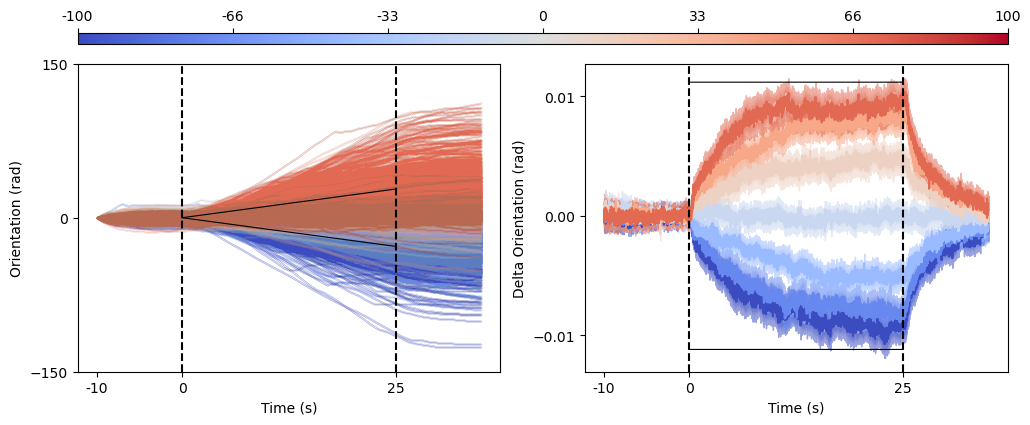

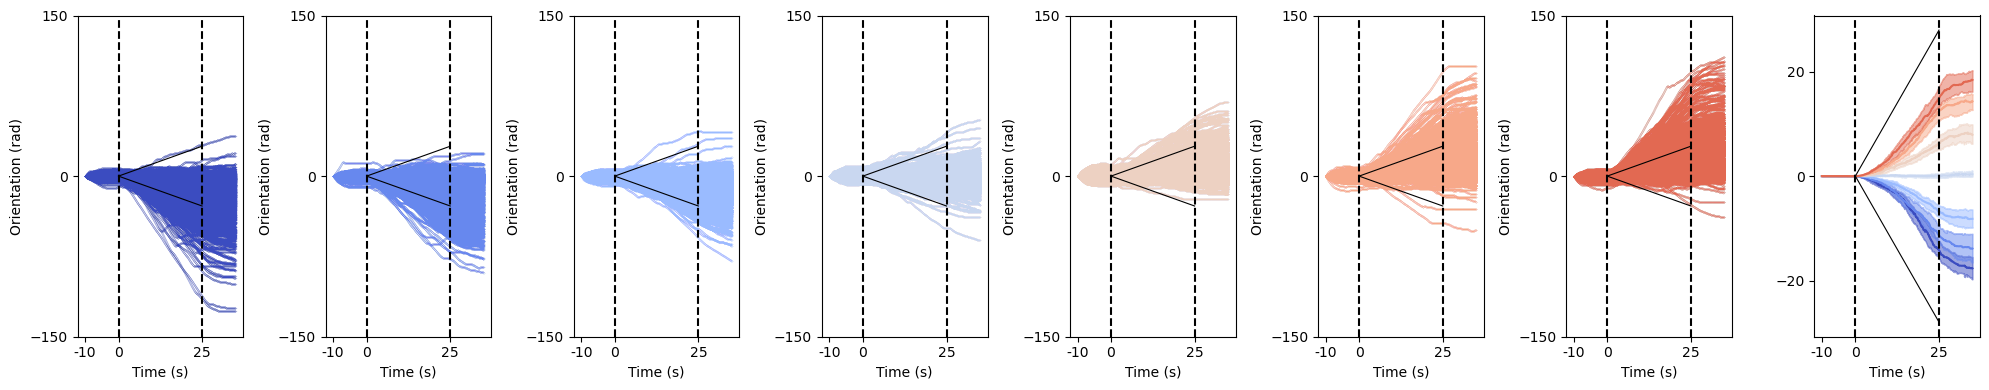

In [67]:
plot_yaw_angular_velocity(df_combined,analysis_methods,init_frame,end_frame)

In [ ]:
vr_groups = df.groupby('VR_no')
for vr_no, entries in vr_groups:
    plot_preview_summary(entries,analysis_methods,vr_no)